In this notebook we explore how the biases depend on thehalo masses included in the calculation

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import qest
from cosmoblender import biases
import os

/var/folders/zf/xwwhf0ps6yx93zy9ttqm3mm80000gn/T/ipykernel_66551/1461453364.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/mpi.py (No module named 'pypar'). Could not load pbs or pypar. MPI will not be used.
IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/shts/__init__.py (No module named 'fsht'). Try running 'python setup.py install' or 'python setup.py build_ext --inplace' from the quicklens directory.


In [2]:
# Directory to save to and load cached calculations from
outdir = './cached_calcs/'

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

In [4]:
# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = False 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

In [5]:
lmax = 4000
SPT_properties = {'nlev_t': np.array([0.]),
                  'beam_size':np.array([1]), 'lmax':lmax}

In [14]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

which_bias = 'tsz' #'tsz' or 'cib'

m_min_array = np.array([1e10, 1e11, 1e12, 1e13, 1e14])

if which_bias == 'cib':
    # For CIB, we found no difference between nz=150 and nz=50 for the prim bispec and trispec, so we run with nz=50 so we can also compute the sec bispec in a reasonable time
    nZs = 50 
    nMasses = 70  #40
    m_min = 1e7

    z_max = 5.
    #m_min_array = np.array([1e6, 1e8, 1e10, 1e12])

elif which_bias == 'tsz':
    # For tSZ we DO find big differences between nz=150 and nz=50 when running up to zmax=7 or so. But further testing reveals that the calculation is fully converged by z=3 or so, so we can run to lower z and get away with lower nz as well
    nZs = 50
    nMasses = 50
    m_min = 1e7

    z_max = 2

# Set CIB halo model
cib_model='viero'

In [15]:
# What maximum halo mass cut to use
massCut_Mvir = None #2e14

if massCut_Mvir is None:
    print('Using no mass cut -- i.e. infinity')
    mcut_str = ''
else:
    print('Using mass cut of Mvir = %s Msun/h'%(as_si(massCut_Mvir,2)))
    mcut_str = '_Mcut%s'%(as_si(massCut_Mvir,2))
print(mcut_str)

Using no mass cut -- i.e. infinity



Note that you can typically skip the following cell since arrays are already saved to file

In [23]:
#
#
# Calculate the biases
#
#
get_secondary_bispec_bias = True
bin_width_out_second_bispec_bias = 100
parallelise_secondbispec = False

if massCut_Mvir is None:
    experiment = qest.experiment(**SPT_properties, **fg_cleaning_dict, nx_secbispec=256, dx_arcmin_secbispec=0.1)
else:
    experiment = qest.experiment(**SPT_properties, **fg_cleaning_dict, nx_secbispec=256, dx_arcmin_secbispec=0.1, massCut_Mvir=massCut_Mvir)

for i, m_min in enumerate(m_min_array):
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max, m_min=m_min)
    
    if which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec,
                                    bin_width_out_second_bispec_bias=bin_width_out_second_bispec_bias)
        experiment.save_biases(output_filename='./cib_dict_with_biases_m_min{}_nzs{}{}{}'.format(m_min, nZs, mcut_str))
    elif which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec,
                                    bin_width_out_second_bispec_bias=bin_width_out_second_bispec_bias)
        experiment.save_biases(output_filename='./tsz_dict_with_biases_m_min{}_nzs{}{}'.format(m_min, nZs, mcut_str))
    else:
        raise ValueError('which_bias must be cib or tsz (for now at least)')
        
    print('Completed {}/{}'.format(i+1, len(m_min_array)))

Platform 'METAL' is experimental and not all JAX functionality may be correctly supported!
W0000 00:00:1758606473.028655 51006385 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1758606473.042123 51006385 service.cc:145] XLA service 0x3095915d0 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1758606473.042136 51006385 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1758606473.043330 51006385 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1758606473.043340 51006385 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Max

systemMemory: 32.00 GB
maxCacheSize: 10.67 GB

Completed 1/5
Completed 2/5
Completed 3/5
Completed 4/5
Completed 5/5


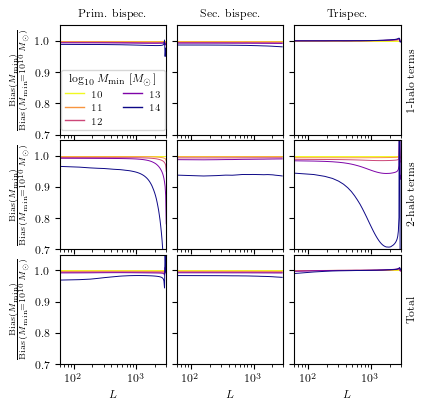

In [ ]:
textwidth = 4

import matplotlib.cm as cm
# Do this on the reverse viridis colormap
colors = cm.plasma(np.linspace(1, 0, len(m_min_array)))

assert which_bias in ['tsz'], 'which_bias must be tsz to run this cell'
foregrounds = np.array(['tsz'])

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(1.1*textwidth, 1.1*textwidth), squeeze=True)

[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'Prim. bispec.', r'Sec. bispec.', r'Trispec.'])]
[ax.set_xlabel(r'$L$') for ax in axes[2, :]]

for foreground in foregrounds:
    for massCut_Mvir, linestyle in zip([massCut_Mvir], ['-', '--']):
        try:
            dict_of_biases_fullcalc = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_m_min{}_nzs{}{}.pkl'.format(foreground, m_min_array[0], nZs, mcut_str))
            
            for col, bias in enumerate(['prim_bispec', 'second_bispec', 'trispec']):
                    if bias=='second_bispec':
                        ells = dict_of_biases_fullcalc['second_bispec_bias_ells']
                    else:
                        ells = dict_of_biases_fullcalc['ells']
                    numerator_of_total = np.zeros((len(ells), len(m_min_array)), dtype='complex128')
                    
                    denom_of_total = dict_of_biases_fullcalc[foreground][bias]['1h'] + dict_of_biases_fullcalc[foreground][bias]['2h']
                    for row, term in enumerate(['1h', '2h','total']):
                        for i, M_min in enumerate(m_min_array):
                            dict_of_biases = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_m_min{}_nzs{}{}.pkl'.format(foreground, M_min, nZs, mcut_str))
                            
                            if term == 'total':
                                total = numerator_of_total[:, i] / denom_of_total
                                axes[row, col].plot(ells, total, label=r'$\log_{10} M_{\rm{min}}=$'+str(np.log10(M_min)), color=colors[i], ls=linestyle)

                            else:
                                numerator_of_total[:, i] += dict_of_biases[foreground][bias][term]
                                axes[row, col].plot(ells, dict_of_biases[foreground][bias][term] / dict_of_biases_fullcalc[foreground][bias][term], color=colors[i])

                            #axes[k].set_title(term+' '+foreground+' '+bias+' biases')
                            plt.gca().set_ylim([0.7, 1.05])
                            plt.gca().set_xlim([60, 3000])
                            plt.gca().set_xscale('log')
        except:
            print('no {} {} bias'.format(foreground, bias))

[axes[i,0].set_ylabel(r'$\frac{\mathrm{Bias}(M_{\mathrm{min}})}{\mathrm{Bias}(M_{\mathrm{min}}=10^{10}\,M_{\mathrm{\odot}})}$') for i in range(3)]

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'1-halo terms', r'2-halo terms', r'Total'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.1)

# Replace the colorbar with a legend to go in the third subplot
[axes[0,0].plot([],[], color=colors[i], lw=1, label=np.log10(m_min_array).astype(int).astype(str)[i]) for i in range(len(m_min_array))]
axes[0,0].legend(title=r'$\log_{10} M_{\rm min}$ [$M_{\odot}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

#plt.savefig(plots_dir+'tsz_convergence_vs_Mmin.pdf', bbox_inches='tight', dpi=1000)

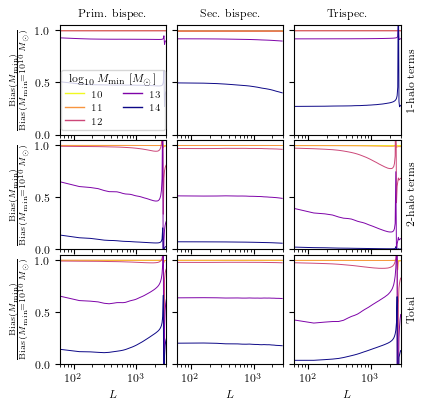

In [ ]:
textwidth = 4

import matplotlib.cm as cm
# Do this on the reverse viridis colormap
colors = cm.plasma(np.linspace(1, 0, len(m_min_array)))

assert which_bias in ['cib'], 'which_bias must be cib to run this cell'
foregrounds = np.array(['cib'])

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(1.1*textwidth, 1.1*textwidth), squeeze=True)

[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'Prim. bispec.', r'Sec. bispec.', r'Trispec.'])]
[ax.set_xlabel(r'$L$') for ax in axes[2, :]]

for foreground in foregrounds:
    dict_of_biases_fullcalc = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_m_min{}_nzs{}{}.pkl'.format(foreground, m_min_array[0], nZs, mcut_str))
    for col, bias in enumerate(['prim_bispec', 'second_bispec', 'trispec']):
        try:
            if bias=='second_bispec':
                ells = dict_of_biases_fullcalc['second_bispec_bias_ells']
            else:
                ells = dict_of_biases_fullcalc['ells']
            numerator_of_total = np.zeros((len(ells), len(m_min_array)), dtype='complex128')
            
            denom_of_total = dict_of_biases_fullcalc[foreground][bias]['1h'] + dict_of_biases_fullcalc[foreground][bias]['2h']
            for row, term in enumerate(['1h', '2h','total']):
                for i, M_min in enumerate(m_min_array):
                    dict_of_biases = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_m_min{}_nzs{}{}.pkl'.format(foreground, M_min, nZs, mcut_str))
                    
                    if term == 'total':
                        total = numerator_of_total[:, i] / denom_of_total
                        axes[row, col].plot(ells, total, label=r'$\log_{10} M_{\rm{min}}=$'+str(np.log10(M_min)), color=colors[i])

                    else:
                        numerator_of_total[:, i] += dict_of_biases[foreground][bias][term]
                        axes[row, col].plot(ells, dict_of_biases[foreground][bias][term] / dict_of_biases_fullcalc[foreground][bias][term], color=colors[i])

                    #axes[k].set_title(term+' '+foreground+' '+bias+' biases')
                    plt.gca().set_ylim([0., 1.05])
                    plt.gca().set_xlim([60, 3000])
                    plt.gca().set_xscale('log')
        except:
            print('Error with foreground {} and bias {}'.format(foreground, bias))
            continue

[axes[i,0].set_ylabel(r'$\frac{\mathrm{Bias}(M_{\mathrm{min}})}{\mathrm{Bias}(M_{\mathrm{min}}=10^{10}\,M_{\mathrm{\odot}})}$') for i in range(3)]

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'1-halo terms', r'2-halo terms', r'Total'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.1)

# Replace the colorbar with a legend to go in the third subplot
[axes[0,0].plot([],[], color=colors[i], lw=1, label=np.log10(m_min_array).astype(int).astype(str)[i]) for i in range(len(m_min_array))]
axes[0,0].legend(title=r'$\log_{10} M_{\rm min}$ [$M_{\odot}$]', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

#plt.savefig(plots_dir+'cib_convergence_vs_Mmin.pdf', bbox_inches='tight', dpi=1000)